# Proches en métro, proches en revenus ?

## *La géographie du réseau de transports en communs en Île-de-France reflète-t-elle la géographie des inégalités de revenus dans la région ?*

## Introduction

*De la Plaine Monceau au quartier des Épinettes on parcourt tout l'espace social, la transition entre les extrêmes étant assurée par un glacis de classes moyennes. Ces contrastes sociaux importants voisinent pourtant à quelques rues près, même si la mixité sociale est menacée par un processus d'embourgeoisement qui fait tache d'huile et ne laisse guère de quartiers à l'écart.*

*Du sud-ouest au nord-est du 17e arrondissement, le parcours est à la fois historique et sociologique, des abords fortunés du parc Monceau aux confins bordés par les boulevards des Maréchaux et leurs HBM (Habitations à bon marché, ancêtres des HLM).*

Pinçon, M. et Pinçon-Charlot, M. (2014). I. Lire Paris. Sociologie de Paris (3e éd., p. 9-26). La Découverte. https://shs.cairn.info/sociologie-de-paris--9782707182623-page-9?lang=fr.

Parce qu'elles sont conçues pour relier des territoires différents, les lignes de transports en commun traversent logiquement des espaces socialement et économiquement hétérogènes. Ainsi, par exemple, l'usager quotidien de la ligne 4 ou du RER A n'occupe pas la même position dans l'échelle sociale selon qu'il se trouve au milieu ou à l'une des extrémités de ces lignes.

Si des territoires économiquement et socialement proches peuvent aussi l'être géographiquement, les transports en commun rapprochent des espaces parfois très différentes, et constituent ainsi des axes le long desquels peuvent s'observer les contrastes.

Nous développons ici deux axes de réponse à cette question. Nous verrons dans un premier temps que les revenus tendent à décroître à mesure que l'excentricité par rapport au réseau augmente, y compris à distance géographique équivalente. Dans un second temps, nous verrons que le long de certaines lignes, des stations très proches affichent des revenus moyens très différents.

## Méthodologie

## Données

Les deux principales sources de données utilisées pour ce projet sont les données IDFM et les données Filosofi.

In [1]:
from pretraitement_donnees import telecharger_zip, URL_ZIP_FILOSOFI, URL_ZIP_IDFM
import numpy as np
import os
import pandas as pd
import geopandas as gpd                    
import matplotlib.pyplot as plt            
import statsmodels.formula.api as smf      

### Données FiLoSoFi (2021)

Les données FiLoSoFi sont des données territoriales calculées par l'Insee, sur des carreaux de 200mx200m, ici pour l'année 2021. Lorsque les carreaux contiennent moins de 11 ménages, les données sont imputées pour préserver le secret statistique.

In [2]:
from pretraitement_donnees import charger_filosofi, indicateurs_filosofi, definir_quantiles, construire_centres_carreaux
from visualisation_donnees import generer_carte_filosofi
import geopandas as gpd

telecharger_zip(URL_ZIP_FILOSOFI, "filosofi")  # Ne télécharge que si data/filosofi n'existe pas

df_filosofi = charger_filosofi("data/filosofi/france_metro/carreaux_200m_met.shp")
df_filosofi = indicateurs_filosofi(df_filosofi)  # nv = niveau de vie moyen par habitant

### Données IDFM (2026)

Île-de-France Mobilités (IDFM) propose les données 

In [3]:
from pretraitement_donnees import charger_arrets, charger_routes, charger_routes_etendu, charger_horaires, charger_parcours, charger_stations, charger_trips, construire_lignes_idfm, construire_stations, construire_positions_stations, construire_aretes, construire_graphe_reseau
telecharger_zip(URL_ZIP_IDFM, "idfm")  # Ne télécharge que si data/idfm n'existe pas
print(os.listdir("data/idfm"))

['transfers.txt', 'agency.txt', 'calendar_dates.txt', 'stop_times.txt', 'shapes.txt', 'object_codes_extension.txt', 'trips.txt', 'ticketing_deep_links.txt', 'attributions.txt', 'pathways.txt', 'stops.txt', 'booking_rules.txt', 'calendar.txt', 'routes.txt']


Les données IDFM ne contiennent pas moins de 14 fichiers .txt différents, au format CSV. Nous ne chargeons que ceux dont nous avons besoin pour construire les lignes et calculer les temps de trajet entre deux stations. 

In [4]:
print(len(pd.read_csv("data/idfm/routes.txt"))) 

2027


Il y a 2027 lignes différentes. Pour faciliter la visualisation et les traitements, nous décidons de ne garder seulement le réseau ferré (métro, RER, Transilien, tram)

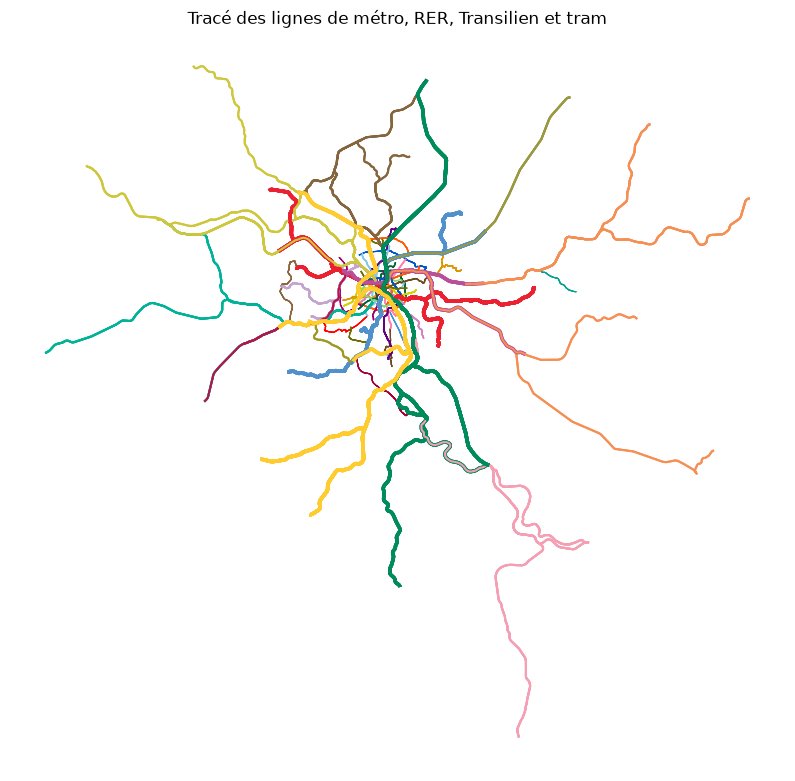

In [5]:
df_routes = charger_routes_etendu("data/idfm") # Lignes selon leur type : métro, RER, Transilien et tram
df_trips = charger_trips("data/idfm", df_routes) # Trains qui traversent chaque ligne
df_parcours = charger_parcours("data/idfm", df_trips) # Géométrie du parcours suivi par les trains de notre sélection

gpd_idfm = construire_lignes_idfm(df_parcours) # Passage en GeoPandas, avec changement de projection

EPAISSEUR = {"metro": 1, "tram": 0.8, "transilien": 1.5, "rer": 2.5} # Épaisseur du trait selon le type de ligne

ax = gpd_idfm.plot(
    color="#" + gpd_idfm["route_color"], # Couleurs officielles des lignes
    linewidth=gpd_idfm["mode"].map(EPAISSEUR).values, # RER plus épais, tram plus fin
    figsize=(10, 10),
)
ax.set_title("Tracé des lignes de métro, RER, Transilien et tram")
ax.set_axis_off()

Nous obtenons un GeoDataFrame qui contient le tracé géographique de chaque ligne de métro / RER. Remarquons que certaines lignes possèdent de nombreux trains, auxquels correspondent de nombreux tracés.

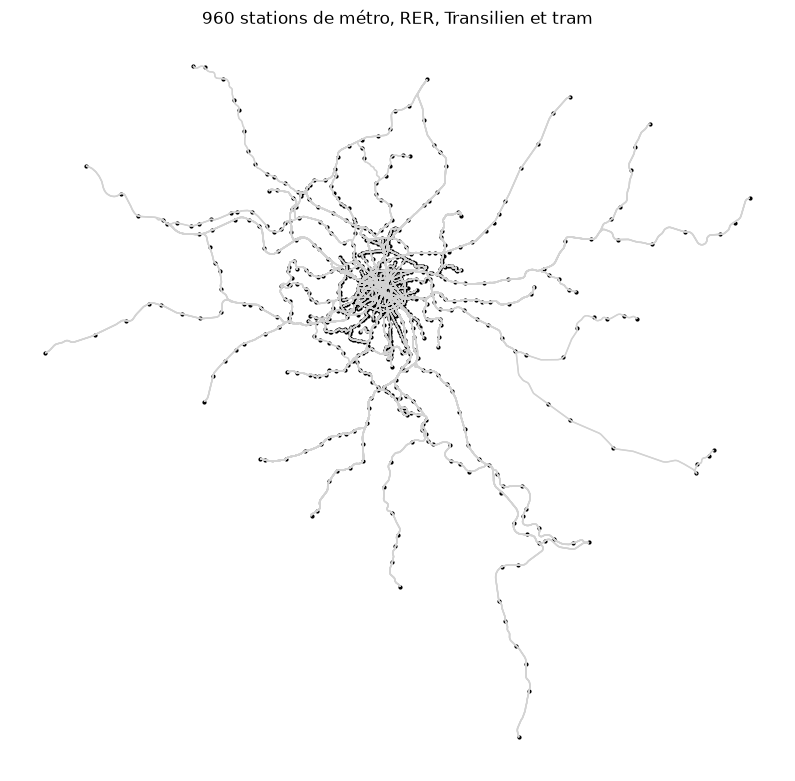

In [6]:
df_arrets = charger_arrets("data/idfm", df_trips) # Arrêts desservis par les trains
df_stations = charger_stations("data/idfm", df_arrets) # Stations desservies par les trains (plusieurs arrêts pour une même station)
gpd_stations = construire_stations(df_stations) # Position des stations (une ligne par station)

# Position des stations avec le nom de leur ligne (une ligne par couple station-ligne)
# -> utile pour l'ordre des stations et les cartes par ligne
gpd_stations_lignes = gpd.GeoDataFrame(
    df_stations,
    geometry=gpd.points_from_xy(df_stations["stop_lon"], df_stations["stop_lat"]),
    crs="EPSG:4326",
).to_crs("EPSG:2154")

ax = gpd_idfm.plot(color="lightgrey", linewidth=1, figsize=(10, 10)) # Lignes en fond
gpd_stations.plot(ax=ax, color="black", markersize=4)
ax.set_title(f"{len(gpd_stations)} stations de métro, RER, Transilien et tram")
ax.set_axis_off()

Nous obtenons 960 stations sur l'ensemble du réseau ferré (métro, RER, Transilien et tram).

In [7]:
df_horaires = charger_horaires("data/idfm", df_trips) # Horaires des trains à chaque arrêt
df_aretes = construire_aretes(df_horaires) # Calcul du temps minimal entre deux stations consécutives
graphe_reseau = construire_graphe_reseau(df_aretes) # Graphe orienté pondéré par le temps de transport entre les stations

print(df_aretes.describe())
print(graphe_reseau)

             temps
count  2516.000000
mean      3.162725
std       3.277788
min       0.733333
25%       1.516667
50%       2.325000
75%       3.608333
max      42.333333
DiGraph with 960 nodes and 2405 edges


Nous obtenons 2516 trajets entre deux stations consécutives, comptés dans chaque sens et pour chaque ligne : un tronçon desservi par plusieurs lignes apparaît donc plusieurs fois. Dans le graphe du réseau, où nous ne gardons que la ligne la plus rapide pour chaque tronçon, il reste 2405 liaisons.

### Données MOBPRO (2023)
Les données MOBPRO (recensement 2023, Insee) décrivent les trajets domicile-travail des actifs : commune de résidence, catégorie socioprofessionnelle (CSP) et mode de transport principal. Chaque ligne représente plusieurs personnes réelles, selon son poids `IPONDI`.

In [8]:
from pretraitement_donnees import URL_MOBPRO, telecharger_fichier, charger_mobpro, indicateurs_mobpro

telecharger_fichier(URL_MOBPRO, "RP2023_mobpro.parquet")  # Ne télécharge que si le fichier n'est pas dans data/

df_mob = charger_mobpro("data/RP2023_mobpro.parquet") # Actifs qui habitent en Île-de-France (région 11)
df_mob = indicateurs_mobpro(df_mob) # CSP et mode de transport en clair, lieu de résidence (arrondissement à Paris)

print(f"{len(df_mob):,} personnes interrogées".replace(",", " "))
print(f"{df_mob['IPONDI'].sum():,.0f} actifs franciliens représentés".replace(",", " "))

1 716 315 personnes interrogées
5 760 838 actifs franciliens représentés


L'échantillon compte environ 1,7 million de personnes interrogées, qui représentent, grâce aux poids `IPONDI`, environ 5,8 millions d'actifs franciliens.

### Contours des communes et des arrondissements
Pour relier les stations et les données MOBPRO, nous utilisons les contours des communes d'Île-de-France, Paris étant découpé en ses 20 arrondissements.

Ni MOBPRO, qui ne fournit qu'un code de commune, ni Filosofi, limité aux carreaux habités, ne contiennent la forme des communes. Nous utilisons donc des contours officiels, indispensables pour situer chaque station dans sa commune et représenter les données sur une carte.

In [9]:
from pretraitement_donnees import URL_COMMUNES, URL_ARRONDISSEMENTS, telecharger_fichier

# Communes d'Île-de-France (fichier public GitHub)
telecharger_fichier(URL_COMMUNES, "communes.geojson")
communes = gpd.read_file("data/communes.geojson")
communes = communes.rename(columns={"code": "INSEE_COM"})
communes = communes.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]

# Arrondissements de Paris (open data de la Ville de Paris)
telecharger_fichier(URL_ARRONDISSEMENTS, "arrondissements.geojson")
arr = gpd.read_file("data/arrondissements.geojson")
arr = arr.rename(columns={"c_arinsee": "INSEE_COM"})
arr["INSEE_COM"] = arr["INSEE_COM"].astype(int).astype(str)  # ex : "75113"
arr["nom"] = arr["INSEE_COM"].str[-2:].astype(int).map(lambda n: "1er" if n == 1 else f"{n}ème")
arr = arr.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]

# On remplace "Paris" (75056) par ses 20 arrondissements
communes = pd.concat([communes[communes["INSEE_COM"] != "75056"], arr], ignore_index=True)

print(f"{len(communes)} communes et arrondissements")

1295 communes et arrondissements


## I. Temps en transports, distance géographique, proximité économique

Dans cette partie, nous calculons pour chaque station le temps de transport par rapport à plusieurs pôles, et définissons comme temps de transport de référence le temps le moins élevé.

### I.1 Le temps de trajet selon la distance

In [10]:
from reg import (
    preparer_stations_chatelet, graphique_temps_distance,
    preparer_carreaux, graphique_niveau_vie,
)

# Temps de trajet et distance de chaque station jusqu'à Châtelet
df_reg, df_temps, chatelet = preparer_stations_chatelet(gpd_stations, graphe_reseau)

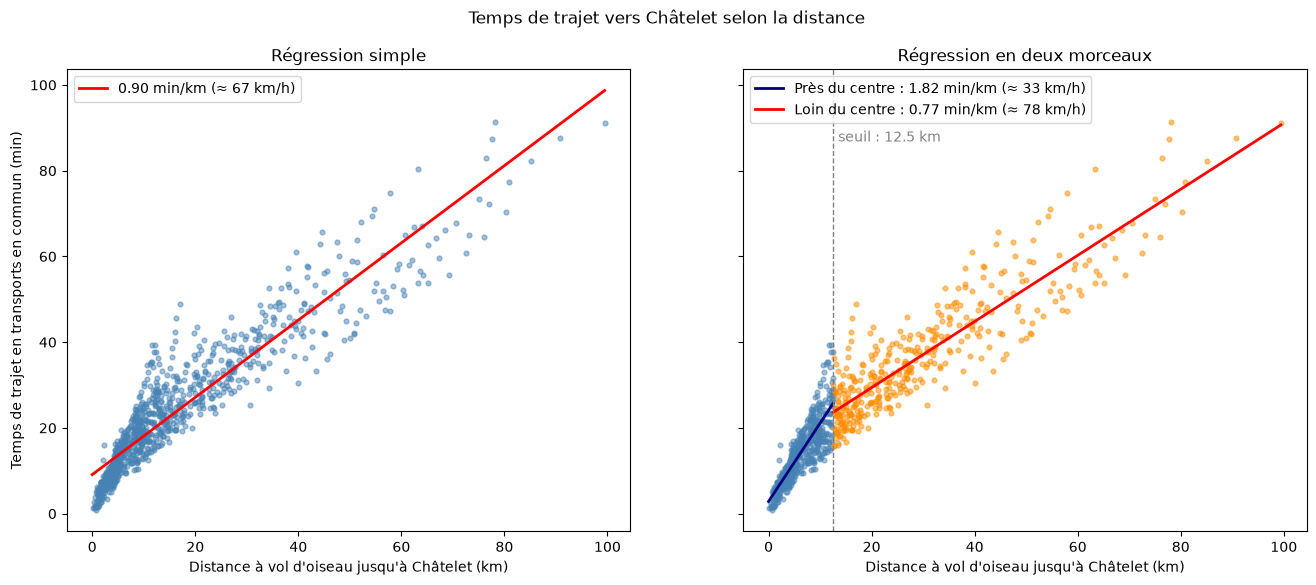

In [11]:
seuil = graphique_temps_distance(df_reg)

Le seuil de 12,5 km correspond à la limite de la petite couronne : en deçà, le métro dessert finement le territoire mais lentement (1,8 min par km) ; au-delà, seuls le RER et le Transilien prennent le relais, plus rapides (0,8 min par km) mais moins bien répartis. Les communes situées juste après cette limite sont les plus pénalisées : trop loin pour le métro, parfois mal reliées au RER, elles connaissent les temps de trajet les plus élevés au regard de leur distance à Paris.


In [12]:
# Distance et temps de trajet vers Châtelet pour chaque carreau de 200 m
carreaux = preparer_carreaux(df_filosofi, gpd_stations, df_temps, chatelet)

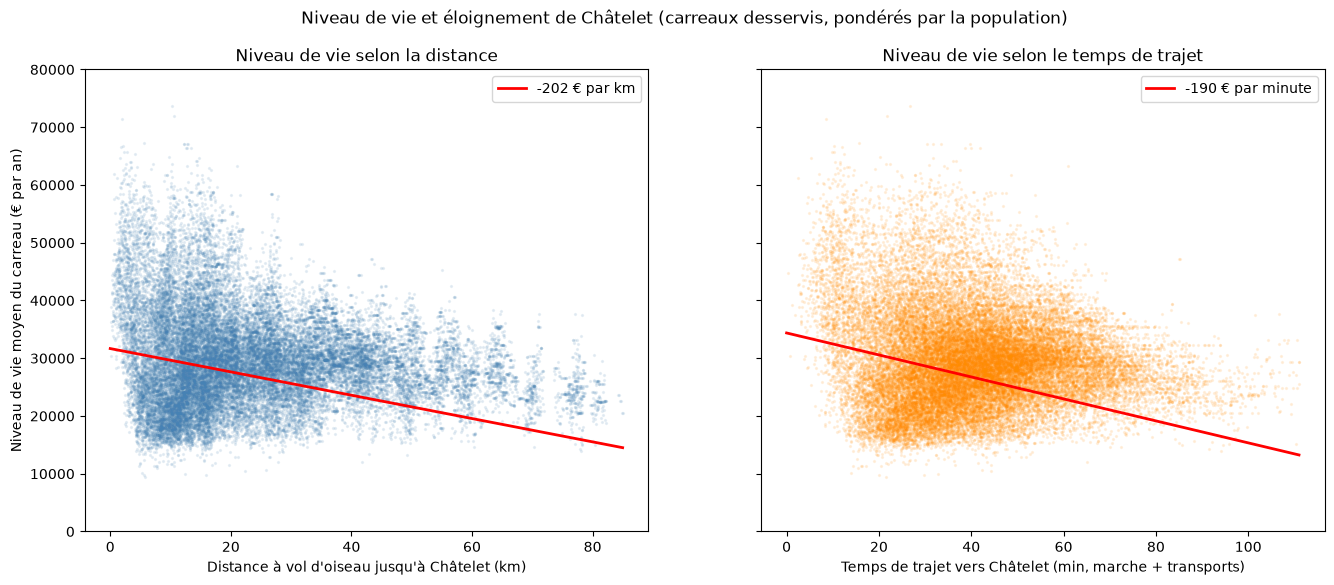

Niveau de vie ~ distance
                 Coef.  Std.Err.  P>|t|
Intercept    31676.583    75.829    0.0
distance_km   -201.941     4.119    0.0
R² = 0.065

Niveau de vie ~ temps
                 Coef.  Std.Err.  P>|t|
Intercept    34379.339   109.129    0.0
temps_total   -190.325     3.351    0.0
R² = 0.085



In [13]:
m_dist, m_temps = graphique_niveau_vie(carreaux)

Le niveau de vie diminue significativement avec l'éloignement de Châtelet : -202€ par an pour chaque kilomètre, et -190€ pour chaque minute de trajet supplémentaire. Le temps de trajet explique légèrement mieux les écarts de niveau de vie que la distance (R² de 8,5% contre 6,5%), ce qui suggère que l'accessibilité réelle compte davantage que l'éloignement géographique. Ces deux variables n'expliquent toutefois qu'une faible part des inégalités, qui dépendent surtout de la localisation des quartiers (ouest aisé, nord-est plus modeste).


## II. Écarts entre des stations consécutives, hétérogénéité des lignes

In [14]:
from reg import carte

# Toutes les données dont les cartes ont besoin, regroupées en un seul "paquet"
donnees_cartes = dict(
    df_mob=df_mob, communes=communes, arr=arr,
    gpd_idfm=gpd_idfm, gpd_stations_lignes=gpd_stations_lignes,
)

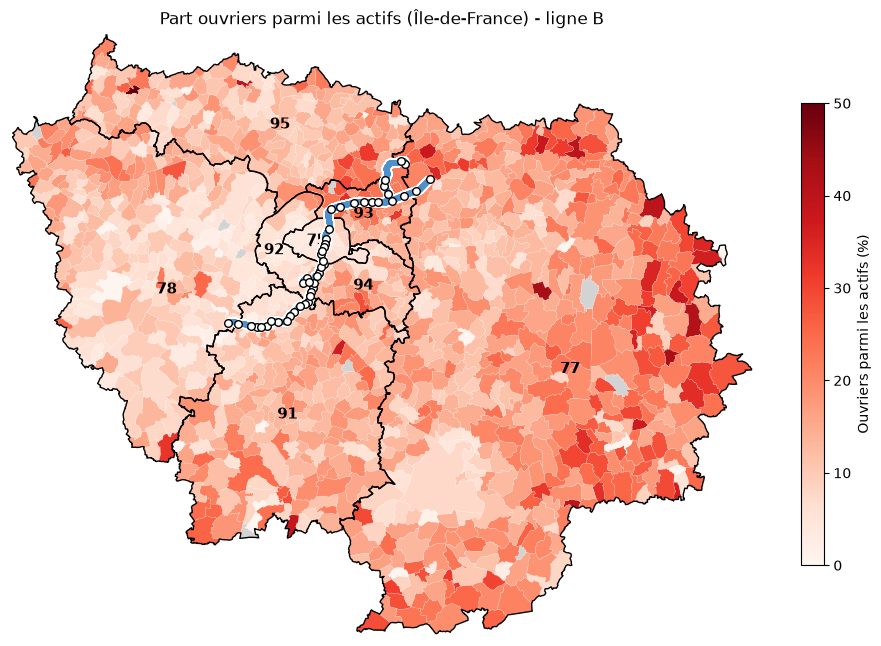

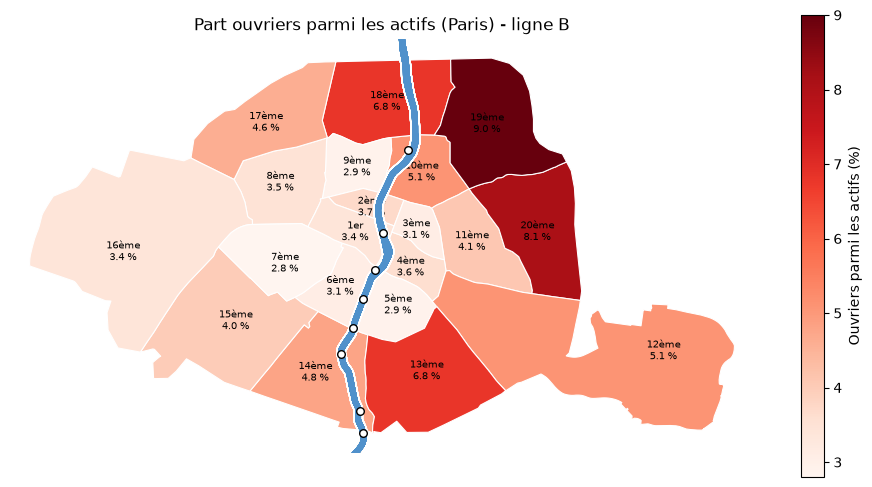

In [15]:
carte("Ouvriers", zone="idf", ligne="B", **donnees_cartes)    # RER B sur toute l'Île-de-France
carte("Ouvriers", zone="paris", ligne="B", **donnees_cartes)  # RER B dans Paris

In [16]:
from reg import resume_ligne

# Découpage du RER B : Paris, banlieue nord, banlieue sud
zones_rer_b = {
    "Paris": ["75"],
    "Banlieue nord": ["93", "95", "77"],
    "Banlieue sud": ["92", "94", "91", "78"],
}

gares_b = resume_ligne("B", "Ouvriers", zones=zones_rer_b, **donnees_cartes)

Ligne B : part ouvriers parmi les actifs

               Gares  Moyenne (%)  Min (%)  Max (%)
zone                                               
Banlieue nord     15         24.0     20.8     33.5
Banlieue sud      25          6.6      4.2     10.0
Paris              7          3.9      2.9      5.1

Part la plus forte :
                   stop_name          nom          zone  part
La Courneuve - Aubervilliers    Courneuve Banlieue nord  33.5
              Sevran - Livry       Sevran Banlieue nord  26.2
         Sevran - Beaudottes       Sevran Banlieue nord  26.2
             Le Blanc-Mesnil Blanc-Mesnil Banlieue nord  25.9
                      Drancy       Drancy Banlieue nord  23.7

Part la plus faible :
              stop_name    nom         zone  part
             Port Royal   5ème        Paris   2.9
Saint-Michel Notre-Dame   5ème        Paris   2.9
             Luxembourg   6ème        Paris   3.1
  Châtelet - Les Halles    1er        Paris   3.4
                 Sceaux Sceaux 

Le RER B relie des territoires socialement très différents. Dans Paris, il traverse des arrondissements où les ouvriers sont rares : 3,9 % des actifs en moyenne autour des sept gares parisiennes, avec un minimum de 2,9 % dans le 5e arrondissement (Saint-Michel Notre-Dame, Port-Royal). En dehors de Paris, la part d'ouvriers est nettement plus élevée : 13 % en moyenne autour des gares de banlieue, soit plus de trois fois plus qu'à Paris.

Mais la banlieue n'est pas homogène pour autant. Au nord, en Seine-Saint-Denis, les communes desservies comptent en moyenne 24 % d'ouvriers parmi leurs actifs, et jusqu'à 33,5 % à La Courneuve, soit plus de dix fois plus qu'à Saint-Michel, à moins de 15 minutes de trajet. Au sud, dans les Hauts-de-Seine et l'Essonne, cette part retombe à 6,6 % en moyenne, et à 4,2 % seulement à Sceaux (Robinson), presque au niveau de Paris. Une même ligne relie donc un nord populaire et un sud aisé, en passant par un centre parisien où les ouvriers sont presque absents.

In [17]:
resume_ligne("14", "Cadres", **donnees_cartes)    # une ligne Transilien

Ligne 14 : part cadres parmi les actifs

          Gares  Moyenne (%)  Min (%)  Max (%)
zone                                          
Banlieue      9         29.1     18.7     39.0
Paris        12         53.2     46.9     57.0

Part la plus forte :
        stop_name   nom  zone  part
        Pyramides   1er Paris  57.0
        Madeleine  8ème Paris  56.2
Gare Saint-Lazare  8ème Paris  56.2
         Châtelet  4ème Paris  55.6
  Porte de Clichy 17ème Paris  55.5

Part la plus faible :
                            stop_name                 nom     zone  part
                 Saint-Denis - Pleyel         Saint-Denis Banlieue  18.7
    Aéroport d’Orly (Terminaux 1-2-3) Paray-Vieille-Poste Banlieue  20.1
Chevilly-Larue (Marché International)      Chevilly-Larue Banlieue  23.5
       Thiais - Orly (Pont de Rungis)              Thiais Banlieue  24.9
                      L'Haÿ-les-Roses       Haÿ-les-Roses Banlieue  29.7
